# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- **Name:* Muhammad Sufian*
- **Student ID:* 023-24-0007*
- **Section:* B*
- **GitHub:* https://github.com/msufianchoohan*
- **Kaggle:* https://www.kaggle.com/mohammadsufian3232*
- **Dataset:** Mall Customers (Kaggle) + Wine (UCI)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python and https://archive.ics.uci.edu/dataset/109/wine

### Before You Start
- You studied K-Means in the lecture. This notebook does not teach it again; it makes you use it, test it and question it.
- There is **no target column**: no train/test split and no accuracy. Judge results by distances, silhouette, plots and common sense.
- Use `SEED = 42`. Write an interpretation under every table and plot. Place `Mall_Customers.csv` in the same folder as this notebook.
- `from sklearn.datasets import load_wine` loads the Wine data (no download needed).


---

## Part 0 — Setup and First Look (10 minutes)

Today there is no target column. The Mall Customers data has no 'right answer' for each customer, so we do not split into train and test and we cannot use accuracy. You will find groups with K-Means (your lecture) and judge them by distance, silhouette and common sense.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |


**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, PCA, load_wine, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [1]:
# YOUR CODE HERE
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

SEED = 42

### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.


In [2]:
# YOUR CODE HERE
df = pd.read_csv("Mall_Customers.csv")
df = df.rename(columns={"Annual Income (k$)": "Income", "Spending Score (1-100)": "Spending"})

print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print(df["Gender"].value_counts())
print(df[["Age", "Income", "Spending"]].describe().round(2))

Shape: (200, 5)
Missing values: 0
Duplicate rows: 0
Gender
Female    112
Male       88
Name: count, dtype: int64
          Age  Income  Spending
count  200.00  200.00    200.00
mean    38.85   60.56     50.20
std     13.97   26.26     25.82
min     18.00   15.00      1.00
25%     28.75   41.50     34.75
50%     36.00   61.50     50.00
75%     49.00   78.00     73.00
max     70.00  137.00     99.00


### Task 0.2 — Look at the data before clustering

Use your eyes first: draw three scatter plots side by side.

1. Draw Spending vs Income, Spending vs Age and Income vs Age (one row of three plots, axis labels and titles).


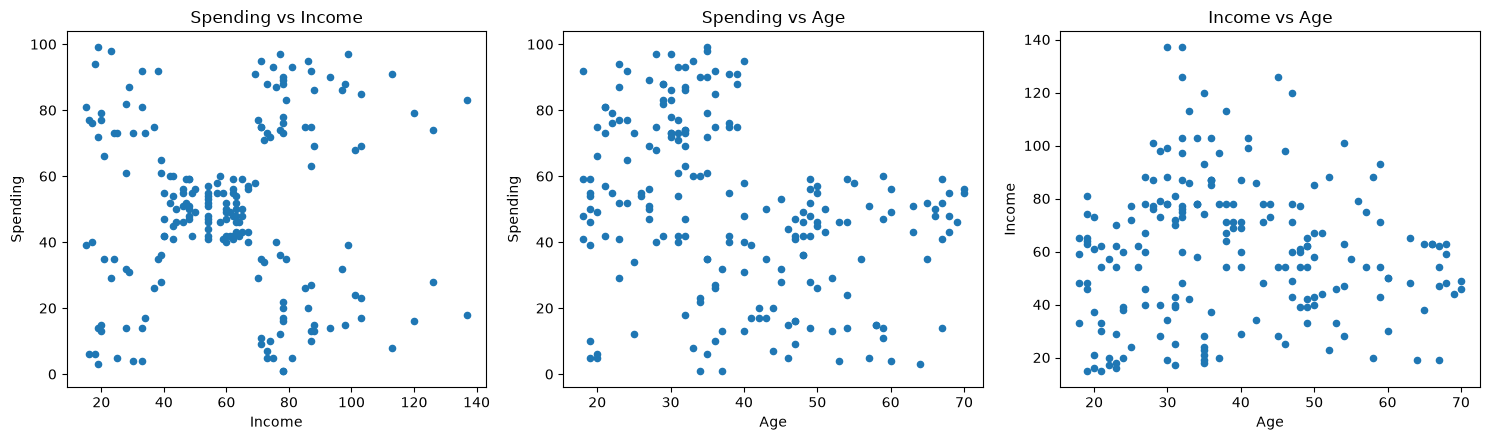

In [3]:
# YOUR CODE HERE
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
pairs = [("Income", "Spending"), ("Age", "Spending"), ("Age", "Income")]
for ax, (x, y) in zip(axes, pairs):
    ax.scatter(df[x], df[y], s=20)
    ax.set_xlabel(x); ax.set_ylabel(y); ax.set_title(f"{y} vs {x}")
plt.tight_layout(); plt.show()

**Questions** (answer with your own numbers)

(a) How many groups can you see by eye in each of the three plots? Which plot shows the groups most clearly?

(b) Why can we not use accuracy or a train/test split to judge a clustering result?



**Your answers:**

(a) In Spending vs Income I can see 5 clear groups, so this plot shows the groups most clearly. In Spending vs Age the points form one wide shape with only about 2 to 3 loose groups, and in Income vs Age I cannot see clear groups.

(b) There is no true label for a customer, so there is nothing to compare the result with (no accuracy), and no test set is needed because the model is not predicting a column. We judge the clusters with inertia, silhouette, plots and common sense.


---

## Part 1 — K-Means From Scratch (35 minutes)

In the lecture you did K-Means by hand. Here you turn your pen-and-paper steps into code, check your answers against the lecture slides, and then build your own K-Means function and compare it with scikit-learn. Using KMeans() inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: |x - m|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |
| Broadcasting | NumPy trick: x[:, None] - m[None, :] gives every point-to-centroid difference in one line. | `x[:, None, :] - C[None, :, :]` |


### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: np.abs(x[:, None] - m[None, :]) has shape (9, 2).
- Cluster of each point: dist.argmin(axis=1).


In [4]:
# YOUR CODE HERE
x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25], dtype=float)
m = np.array([4.0, 11.0])

it = 0
while True:
    it += 1
    dist = np.abs(x[:, None] - m[None, :])          # shape (9, 2)
    labels = dist.argmin(axis=1)                    # nearest centroid
    new_m = np.array([x[labels == k].mean() for k in range(2)])
    print(f"Iteration {it}: C1 = {x[labels == 0].tolist()}  C2 = {x[labels == 1].tolist()}  new centroids = {new_m}")
    if np.allclose(new_m, m):
        break
    m = new_m

inertia = ((x - m[labels]) ** 2).sum()
print("Final centroids:", m, " Inertia:", inertia)


Iteration 1: C1 = [2.0, 4.0, 3.0]  C2 = [10.0, 12.0, 20.0, 30.0, 11.0, 25.0]  new centroids = [ 3. 18.]
Iteration 2: C1 = [2.0, 4.0, 10.0, 3.0]  C2 = [12.0, 20.0, 30.0, 11.0, 25.0]  new centroids = [ 4.75 19.6 ]
Iteration 3: C1 = [2.0, 4.0, 10.0, 12.0, 3.0, 11.0]  C2 = [20.0, 30.0, 25.0]  new centroids = [ 7. 25.]
Iteration 4: C1 = [2.0, 4.0, 10.0, 12.0, 3.0, 11.0]  C2 = [20.0, 30.0, 25.0]  new centroids = [ 7. 25.]
Final centroids: [ 7. 25.]  Inertia: 150.0


### Task 1.2 — Lecture Example 2 in code (two features)

Do the height/weight example: P1 (185, 72), P2 (170, 56), P3 (168, 60), P4 (179, 68), P5 (182, 72), P6 (188, 77). K = 2, start with P1 and P2.

1. Use Euclidean distance and the same loop idea. Print the cluster of every point and the centroids per iteration.
2. Print the final distance table and check one value by hand (the lecture shows d(P3, M2) = 4.47 in the first iteration).


In [5]:
# YOUR CODE HERE
P = np.array([[185, 72], [170, 56], [168, 60], [179, 68], [182, 72], [188, 77]], dtype=float)
M = P[[0, 1]].copy()                                # start with P1 and P2

it = 0
while True:
    it += 1
    dist = np.sqrt(((P[:, None, :] - M[None, :, :]) ** 2).sum(axis=2))   # shape (6, 2)
    labels = dist.argmin(axis=1)
    new_M = np.array([P[labels == k].mean(axis=0) for k in range(2)])
    if it == 1:
        print("d(P3, M2) in the first iteration = %.2f" % dist[2, 1])
    print(f"Iteration {it}: clusters (P1..P6) = {labels + 1}  centroids = {new_M.round(2).tolist()}")
    if np.allclose(new_M, M):
        break
    M = new_M

print("\nFinal distance table:")
print(pd.DataFrame(dist, index=[f"P{i}" for i in range(1, 7)], columns=["M1", "M2"]).round(2))

d(P3, M2) in the first iteration = 4.47
Iteration 1: clusters (P1..P6) = [1 2 2 1 1 1]  centroids = [[183.5, 72.25], [169.0, 58.0]]
Iteration 2: clusters (P1..P6) = [1 2 2 1 1 1]  centroids = [[183.5, 72.25], [169.0, 58.0]]

Final distance table:
       M1     M2
P1   1.52  21.26
P2  21.13   2.24
P3  19.76   2.24
P4   6.19  14.14
P5   1.52  19.10
P6   6.54  26.87


### Task 1.3 — Write your own K-Means function

Write my_kmeans(X, init_centroids, max_iter=100) for any number of features.

1. Return four things: labels, final centroids, inertia and the number of iterations.
2. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
3. Think about what to do if a cluster ends up empty (keep its old centroid).


In [6]:
# YOUR CODE HERE
def my_kmeans(X, init_centroids, max_iter=100):
    X = np.asarray(X, dtype=float)
    C = np.asarray(init_centroids, dtype=float).copy()
    for it in range(1, max_iter + 1):
        dist = np.sqrt(((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=2))   # assign step
        labels = dist.argmin(axis=1)
        new_C = C.copy()
        for k in range(len(C)):
            if (labels == k).any():                                          # update step
                new_C[k] = X[labels == k].mean(axis=0)                       # empty cluster keeps old centroid
        if np.allclose(new_C, C):                                            # convergence
            break
        C = new_C
    inertia = ((X - C[labels]) ** 2).sum()
    return labels, C, inertia, it

In [7]:
# YOUR CODE HERE
lab, cen, inert, n = my_kmeans(x.reshape(-1, 1), [[4], [11]])
print("Centroids:", cen.ravel(), " Inertia:", inert, " Iterations:", n)

Centroids: [ 7. 25.]  Inertia: 150.0  Iterations: 4


### Task 1.4 — Check your function against scikit-learn

Run your function and KMeans on the same data with the same starting centroids and compare.

1. Use X2 = Income and Spending (200 x 2). Take the first 5 rows as the starting centroids.
2. Run my_kmeans. Run KMeans(n_clusters=5, init=<your 5 rows>, n_init=1, tol=0, algorithm='lloyd').
3. Compare iterations, inertia, labels and centroids.


In [8]:
# YOUR CODE HERE
X2 = df[["Income", "Spending"]].values.astype(float)
init5 = X2[:5]

lab_my, cen_my, inert_my, n_my = my_kmeans(X2, init5)
km = KMeans(n_clusters=5, init=init5, n_init=1, tol=0, algorithm="lloyd").fit(X2)

print("Iterations  mine: %d   sklearn: %d" % (n_my, km.n_iter_))
print("Inertia     mine: %.4f   sklearn: %.4f" % (inert_my, km.inertia_))
print("Labels identical:", (lab_my == km.labels_).all())
print("Centroids identical:", np.allclose(cen_my, km.cluster_centers_))

Iterations  mine: 4   sklearn: 4
Inertia     mine: 44448.4554   sklearn: 44448.4554
Labels identical: True
Centroids identical: True


**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

(c) Did your function match scikit-learn exactly (labels, centroids, inertia)? If anything differed, explain why.

(d) What does a centroid mean for a group of customers? Why must the features be numeric for K-Means?



**Your answers:**

(a) After iteration 1 the centroids are 3 and 18. The point 10 is 7 away from 3 but 8 away from 18, so it moves to C1. At the start it was in C2 because it was closer to 11 (distance 1) than to 4 (distance 6).

(b) The loop stops when no centroid changes (iteration 4 gave the same centroids 7 and 25 as iteration 3). It always stops because every assign and update step can only keep or lower the inertia, and there is a limited number of ways to group the points. But it can stop at a local minimum, so the result depends on the starting centroids.

(c) Yes. Both took 4 iterations, the inertia is the same (44448.4554), and the labels and centroids are identical. This is because both use the same starting centroids and the same algorithm.

(d) A centroid is the average customer of the group (its typical Income and Spending). Features must be numeric because K-Means uses means and distances, which cannot be calculated for text.


---

## Part 2 — Choosing K: Elbow and Silhouette (30 minutes)

The algorithm needs K before it starts, but nobody tells us K. The lecture gave two tools: the elbow (inertia) and the silhouette score. Here you use both, then calculate a silhouette by hand to prove you understand it.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Elbow method | Plot inertia for K = 2, 3, 4 ... Inertia always falls as K grows, so look for the K where the fall suddenly becomes small (the bend). | `model.inertia_ in a loop over K` |
| a | Average distance from a point to the other points in its own cluster (smaller = better). | `d[same_cluster].mean()` |
| b | Average distance from the point to the points of the nearest other cluster (larger = better). | `min over other clusters` |
| Silhouette s | s = (b - a) / max(a, b). Close to +1: well placed. Near 0: on the border. Negative: probably in the wrong cluster. | `silhouette_samples(X, labels)` |
| Average silhouette | The mean of s over all points. The K with the highest value is a good candidate. | `silhouette_score(X, labels)` |


### Task 2.1 — Elbow and silhouette for K = 2 to 10

Decide how many customer groups exist using Income and Spending (X2).

1. For K = 2 to 10 fit KMeans(n_clusters=K, n_init=10, random_state=SEED) and record the inertia and the average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.


 K     Inertia  Silhouette
 2 181363.5960      0.2969
 3 106348.3731      0.4676
 4  73679.7890      0.4932
 5  44448.4554      0.5539
 6  37233.8145      0.5398
 7  30241.3436      0.5288
 8  25036.4176      0.4548
 9  21916.7948      0.4561
10  20072.0709      0.4411

K with the highest silhouette: 5


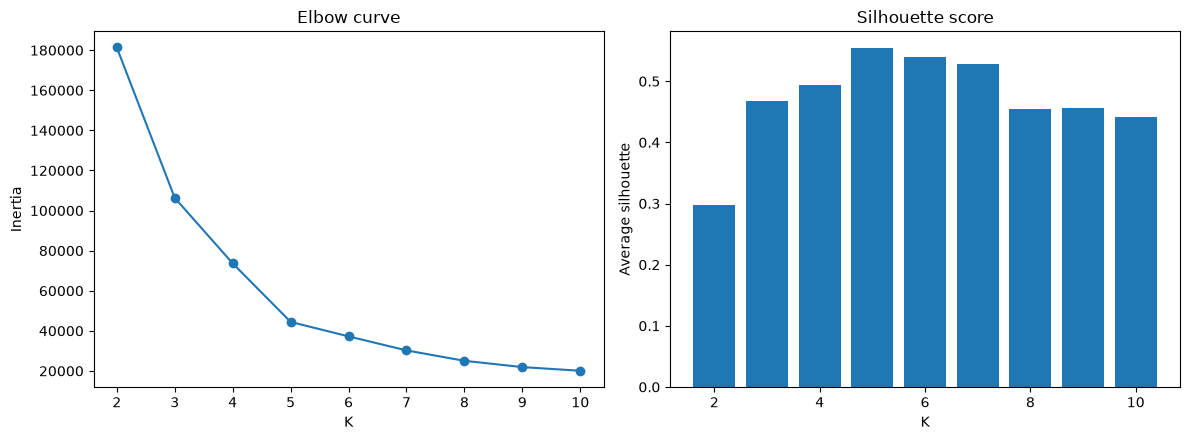

In [9]:
# YOUR CODE HERE
rows = []
for k in range(2, 11):
    m = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X2)
    rows.append({"K": k, "Inertia": m.inertia_, "Silhouette": silhouette_score(X2, m.labels_)})
tab = pd.DataFrame(rows)
print(tab.round(4).to_string(index=False))
print("\nK with the highest silhouette:", int(tab.loc[tab["Silhouette"].idxmax(), "K"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(tab["K"], tab["Inertia"], "o-")
axes[0].set_xlabel("K"); axes[0].set_ylabel("Inertia"); axes[0].set_title("Elbow curve")
axes[1].bar(tab["K"], tab["Silhouette"])
axes[1].set_xlabel("K"); axes[1].set_ylabel("Average silhouette"); axes[1].set_title("Silhouette score")
plt.tight_layout(); plt.show()

### Task 2.2 — Silhouette by hand

Prove that you understand the formula by calculating it yourself.

1. Fit K = 5. Write a function that returns a, b and s for one point (use only NumPy distances). Apply it to customer 1 (row 0) and compare with silhouette_samples.
2. Show the count, mean and minimum silhouette of every cluster, and the number of customers with a negative silhouette.
3. Draw a silhouette plot of all customers sorted inside each cluster.


In [10]:
# YOUR CODE HERE
km5 = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
lab5 = km5.labels_

def silhouette_one(X, labels, i):
    d = np.sqrt(((X - X[i]) ** 2).sum(axis=1))
    own = labels == labels[i]
    a = d[own & (np.arange(len(X)) != i)].mean()
    b = min(d[labels == k].mean() for k in np.unique(labels) if k != labels[i])
    return a, b, (b - a) / max(a, b)

a, b, s = silhouette_one(X2, lab5, 0)
sil = silhouette_samples(X2, lab5)
print("Customer 1: a = %.4f  b = %.4f  s = %.4f   (silhouette_samples: %.4f)" % (a, b, s, sil[0]))

per = pd.DataFrame({"Cluster": lab5, "s": sil}).groupby("Cluster")["s"].agg(Count="count", Mean="mean", Min="min")
print(per.round(4))
print("Customers with a negative silhouette:", (sil < 0).sum())

Customer 1: a = 24.6404  b = 42.2653  s = 0.4170   (silhouette_samples: 0.4170)
         Count    Mean     Min
Cluster                       
0           81  0.5967  0.1153
1           39  0.5092  0.2254
2           22  0.5990  0.0507
3           35  0.5040 -0.0234
4           23  0.5123 -0.0093
Customers with a negative silhouette: 2


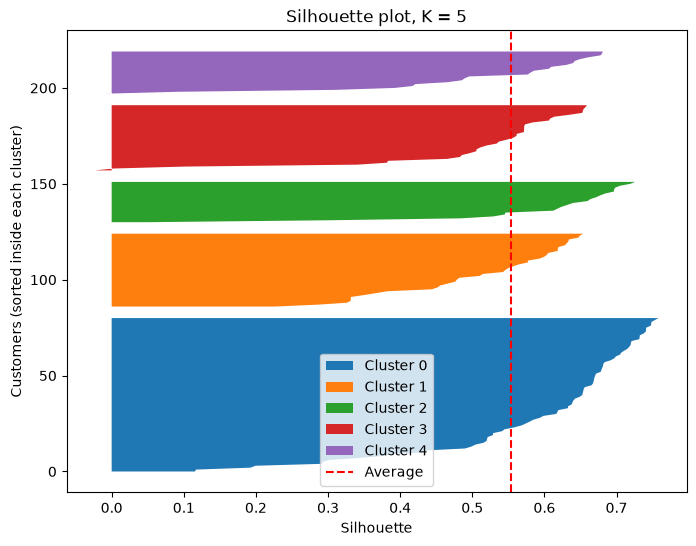

In [11]:
# YOUR CODE HERE
plt.figure(figsize=(8, 6))
y0 = 0
for k in range(5):
    s_k = np.sort(sil[lab5 == k])
    plt.fill_betweenx(np.arange(y0, y0 + len(s_k)), 0, s_k, label=f"Cluster {k}")
    y0 += len(s_k) + 5
plt.axvline(sil.mean(), color="red", ls="--", label="Average")
plt.xlabel("Silhouette"); plt.ylabel("Customers (sorted inside each cluster)")
plt.title("Silhouette plot, K = 5"); plt.legend(); plt.show()


### Task 2.3 — The lecture practice problem

Points 1, 3, 5, 7, 11, 13, 15 with K = 2 and starting centroids 1 and 11 (the 'Practice' slide).

1. Run your my_kmeans on these points and print the final clusters, centroids and iterations.
2. Calculate a, b and s for the points 1, 7 and 11 with your function and compare with silhouette_samples.
3. Also write the iterations on paper (clusters and centroids after each iteration) and keep the photo or notes for your own revision.


In [12]:
# YOUR CODE HERE
pts = np.array([1, 3, 5, 7, 11, 13, 15], dtype=float).reshape(-1, 1)
labp, cenp, inertp, nitp = my_kmeans(pts, [[1], [11]])
for k in range(2):
    print(f"Cluster {k + 1}:", pts[labp == k].ravel().tolist())
print("Centroids:", cenp.ravel(), " Iterations:", nitp)

sp = silhouette_samples(pts, labp)
for p in [1, 7, 11]:
    i = int(np.where(pts.ravel() == p)[0][0])
    a, b, s = silhouette_one(pts, labp, i)
    print("Point %2d: a = %.3f  b = %.3f  s = %.3f   (silhouette_samples: %.3f)" % (p, a, b, s, sp[i]))


Cluster 1: [1.0, 3.0, 5.0, 7.0]
Cluster 2: [11.0, 13.0, 15.0]
Centroids: [ 4. 13.]  Iterations: 3
Point  1: a = 4.000  b = 12.000  s = 0.667   (silhouette_samples: 0.667)
Point  7: a = 4.000  b = 6.000  s = 0.333   (silhouette_samples: 0.333)
Point 11: a = 3.000  b = 7.000  s = 0.571   (silhouette_samples: 0.571)


**Questions** (answer with your own numbers)

(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote the numbers (for example how much the inertia drops from K=4 to 5 and from 5 to 6).

(b) What is the silhouette of customer 1 and what does it tell you? Which cluster has the weakest average silhouette and how many customers have a negative value?

(c) In the practice problem, is point 1 or point 7 less well placed? Explain using a and b.

(d) Why should we never choose K only by the lowest inertia?



**Your answers:**

**(a)** Both methods suggest **K = 5**. The elbow appears at K=5, and it also has the highest silhouette score (**0.5539**).

**(b)** Customer 1 is reasonably placed with a silhouette score of **0.417**. Cluster 3 has the lowest average score (0.5040), and two customers have negative scores.

**(c)** Point 7 is less well placed (**0.333**) than point 1 (**0.667**) because it is closer to another cluster (b = 6 vs. b = 12).

**(d)** Inertia always decreases as K increases, so it cannot determine the best K alone. K=10 has lower inertia (20,072) but a worse silhouette score (0.4411) than K=5 (0.5539).


---

## Part 3 — Starting Points and Stability (20 minutes)

The lecture said 'starting points matter - run several starts and keep the best'. You will now measure how much, using the same data and the same K.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Local minimum | A solution that cannot be improved by the assign/update loop but is not the best possible one. | `A higher final inertia than the best run.` |
| init='random' | Pick K random rows as the starting centroids. | `KMeans(init='random')` |
| init='k-means++' | Pick starting centroids that are far from each other. This is the default and is usually better. | `KMeans(init='k-means++')` |
| n_init | How many different starts to try. scikit-learn keeps the run with the lowest inertia. | `KMeans(n_init=10)` |
| Adjusted Rand Index (ARI) | Agreement between two groupings. 1 = same groups, about 0 = no better than random. It ignores the cluster numbers (cluster 2 in one run can be cluster 4 in another). | `adjusted_rand_score(a, b)` |


### Task 3.1 — 30 different seeds

Measure how often K-Means finds the best answer.

1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in three settings: init='random' with n_init=1, k-means++ with n_init=1, k-means++ with n_init=10.
2. Build a table: setting, number of distinct final inertia values (round to 1 decimal), lowest, highest, and the percentage of runs that reached the best inertia.
3. Draw one histogram of the final inertia values for the three settings.


             Setting  Distinct inertia values   Lowest  Highest  % runs at best
    random, n_init=1                       14 44448.46 91761.98           33.33
 k-means++, n_init=1                        6 44448.46 66733.44           60.00
k-means++, n_init=10                        1 44448.46 44448.46          100.00


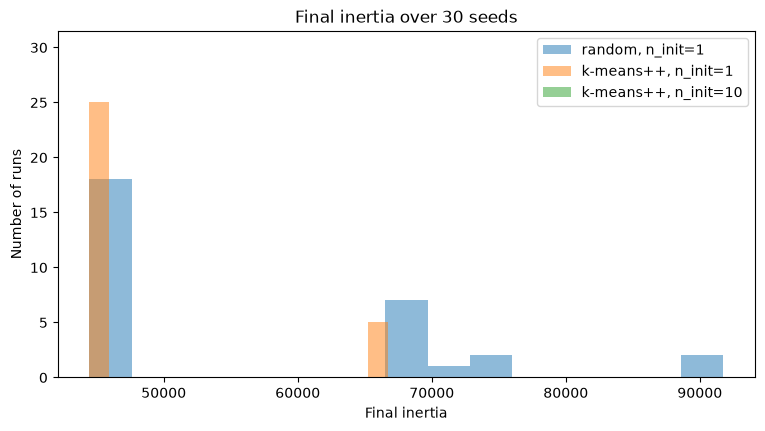

In [13]:
# YOUR CODE HERE
settings = {
    "random, n_init=1": {"init": "random", "n_init": 1},
    "k-means++, n_init=1": {"init": "k-means++", "n_init": 1},
    "k-means++, n_init=10": {"init": "k-means++", "n_init": 10}
}

runs = {
    name: [KMeans(n_clusters=5, random_state=s, **kw).fit(X2)
           for s in range(30)]
    for name, kw in settings.items()
}

best = min(m.inertia_ for r in runs.values() for m in r)

rows = [{
    "Setting": name,
    "Distinct inertia values": len(set(round(m.inertia_, 1) for m in r)),
    "Lowest": min(m.inertia_ for m in r),
    "Highest": max(m.inertia_ for m in r),
    "% runs at best": 100 * np.mean(
        [np.isclose(m.inertia_, best, atol=0.05) for m in r])
} for name, r in runs.items()]

print(pd.DataFrame(rows).round(2).to_string(index=False))

plt.figure(figsize=(9, 4.5))
for name, r in runs.items():
    plt.hist([m.inertia_ for m in r], bins=15, alpha=0.5, label=name)

plt.xlabel("Final inertia")
plt.ylabel("Number of runs")
plt.title("Final inertia over 30 seeds")
plt.legend()
plt.show()

### Task 3.2 — Best run vs worst run

See what a bad local minimum looks like.

1. From the random-init runs take the best and the worst. Draw both clusterings with their centroids side by side.
2. Print their inertia and their ARI.


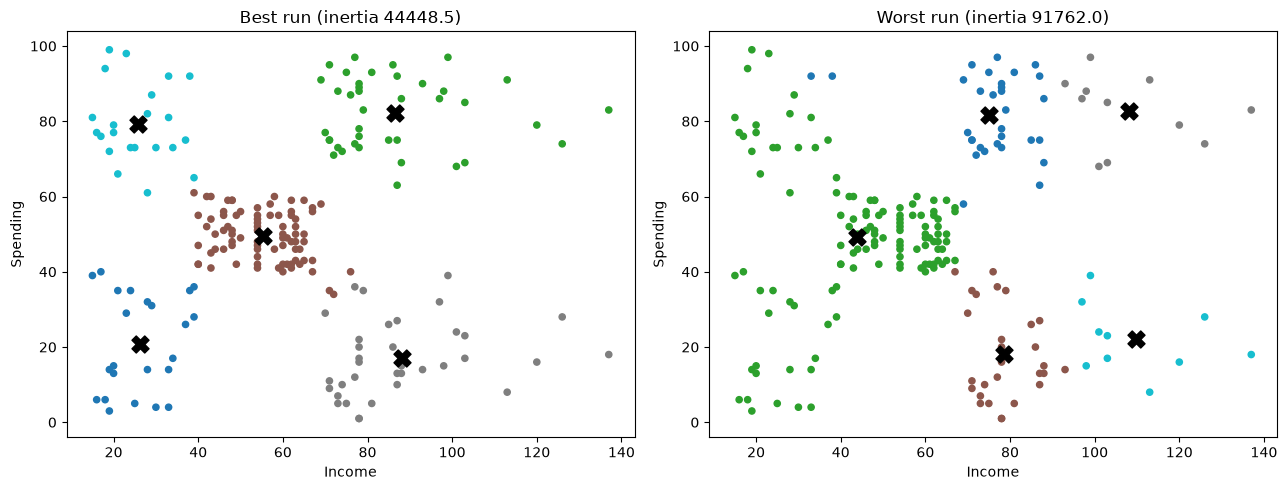

Best inertia: 44448.5   Worst inertia: 91762.0
ARI between best and worst: 0.4553


In [14]:
# YOUR CODE HERE
rr = runs["random, n_init=1"]
best_m = min(rr, key=lambda m: m.inertia_)
worst_m = max(rr, key=lambda m: m.inertia_)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, m, t in zip(axes, [best_m, worst_m], ["Best run", "Worst run"]):
    ax.scatter(X2[:, 0], X2[:, 1], c=m.labels_, cmap="tab10", s=20)
    ax.scatter(m.cluster_centers_[:, 0], m.cluster_centers_[:, 1], c="black", marker="X", s=150)
    ax.set_title("%s (inertia %.1f)" % (t, m.inertia_)); ax.set_xlabel("Income"); ax.set_ylabel("Spending")
plt.tight_layout(); plt.show()
print("Best inertia: %.1f   Worst inertia: %.1f" % (best_m.inertia_, worst_m.inertia_))
print("ARI between best and worst: %.4f" % adjusted_rand_score(best_m.labels_, worst_m.labels_))

**Questions** (answer with your own numbers)

(a) How many different final inertia values did the random-start setting produce, and what percentage of its runs reached the best one? Compare with the other two settings.

(b) Why can the same data and the same K give different answers?

(c) How do k-means++ and n_init help? What did n_init=10 give in your table?

(d) Why do we use ARI to compare two clusterings instead of comparing the label numbers directly?



**Your answers:**

**(a)** Random-start produced 14 different inertia values (33.3% reached the best), k-means++ with `n_init=1` produced 6 (60%), and `n_init=10` produced only 1 (100%).

**(b)** K-means can get stuck in a local minimum, and different starting centroids can produce different results.

**(c)** K-means++ selects better initial centroids, while `n_init=10` runs the algorithm multiple times and keeps the lowest-inertia result.

**(d)** Cluster numbers are just labels, so ARI compares actual groupings rather than their numbers. An ARI of **0.4553** shows that the best and worst random runs produced different groupings.


---

## Part 4 — Scaling: Units Decide the Clusters (25 minutes)

The lecture warned: 'Rs 5000 would swamp 3 visits'. You will prove it twice: once by only changing the unit of Income, and once on the Wine data where the features have very different sizes and the true groups are known.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Feature scaling | Putting all features on a similar scale so that no feature wins the distance only because its numbers are bigger. | `StandardScaler().fit_transform(X)` |
| StandardScaler | z = (x - mean) / std. Every column gets mean 0 and standard deviation 1. | `StandardScaler()` |
| External check | Comparing clusters with known true groups. Possible only for teaching data like Wine. Real clustering problems have no labels. | `adjusted_rand_score(y_true, labels)` |
| PCA (Lab 8) | Reduces many features to 2 so we can draw the data. Used here only for the plot. | `PCA(n_components=2)` |


### Task 4.1 — Change the unit, change the clusters

Use Age and Income with K = 4. Income is in thousands of dollars (15 to 137). Make a second copy where Income is in dollars (multiply by 1000).

1. Cluster four versions: raw k$, raw dollars, scaled k$, scaled dollars (StandardScaler, n_init=10, random_state=SEED).
2. Print ARI between: raw k$ vs raw dollars, scaled k$ vs scaled dollars, raw dollars vs scaled dollars.
3. Draw Age vs Income (in k$) coloured by the clusters of raw k$, raw dollars and scaled.


ARI Raw k$ vs dollars: 0.4897
ARI Scaled k$ vs dollars: 1.0000
ARI Raw vs scaled dollars: 0.3605


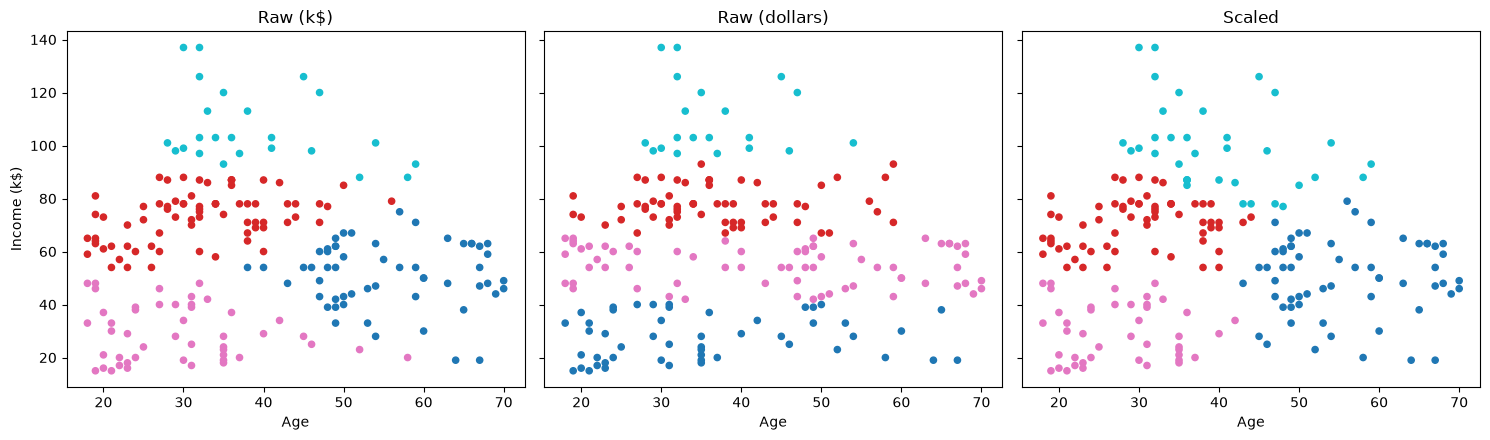

In [15]:
# YOUR CODE HERE
A = df[["Age", "Income"]].values.astype(float)
A_d = A.copy()
A_d[:, 1] *= 1000

def fit4(X, scale=False):
    if scale: X = StandardScaler().fit_transform(X)
    return KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X).labels_

raw_k, raw_d = fit4(A), fit4(A_d)
sc_k, sc_d = fit4(A, True), fit4(A_d, True)

for name, x, y in [
    ("Raw k$ vs dollars", raw_k, raw_d),
    ("Scaled k$ vs dollars", sc_k, sc_d),
    ("Raw vs scaled dollars", raw_d, sc_d)
]:
    print(f"ARI {name}: {adjusted_rand_score(x, y):.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

for ax, lab, title in zip(axes, [raw_k, raw_d, sc_k],
                          ["Raw (k$)", "Raw (dollars)", "Scaled"]):
    ax.scatter(df["Age"], df["Income"], c=lab, cmap="tab10", s=20)
    ax.set_xlabel("Age")
    ax.set_title(title)

axes[0].set_ylabel("Income (k$)")
plt.tight_layout()
plt.show()

### Task 4.2 — Wine data: raw vs scaled

Load the Wine data with load_wine(): 178 wines, 13 chemical measurements, 3 true grape cultivars. The true cultivar is used ONLY to check the result, never to fit K-Means.

1. Print the three largest and the smallest standard deviation of the features.
2. Run KMeans(K=3, n_init=10, random_state=SEED) on the raw data and on the scaled data. For each report ARI against the true cultivar, silhouette score and cluster sizes.


In [16]:
# YOUR CODE HERE
wine = load_wine()
Xw, yw = wine.data, wine.target
sd = pd.Series(Xw.std(axis=0), index=wine.feature_names).sort_values(ascending=False)
print("Three largest standard deviations:")
print(sd.head(3).round(3))
print("Smallest standard deviation:", sd.index[-1], round(sd.iloc[-1], 4))

Three largest standard deviations:
proline              314.022
magnesium             14.242
alcalinity_of_ash      3.330
dtype: float64
Smallest standard deviation: nonflavanoid_phenols 0.1241


In [17]:
# YOUR CODE HERE
Xw_s = StandardScaler().fit_transform(Xw)
km_raw = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(Xw)
km_sc = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(Xw_s)

for name, km_, Xu in [("Raw", km_raw, Xw), ("Scaled", km_sc, Xw_s)]:
    print("%s: ARI = %.4f  silhouette = %.4f  sizes = %s" % (
        name, adjusted_rand_score(yw, km_.labels_), silhouette_score(Xu, km_.labels_),
        np.bincount(km_.labels_).tolist()))

Raw: ARI = 0.3711  silhouette = 0.5711  sizes = [62, 47, 69]
Scaled: ARI = 0.8975  silhouette = 0.2849  sizes = [65, 51, 62]


### Task 4.3 — Draw it

Compare the three views in one picture.

1. Use one PCA of the scaled data and draw three plots with the same axes: true cultivars, raw clusters, scaled clusters.


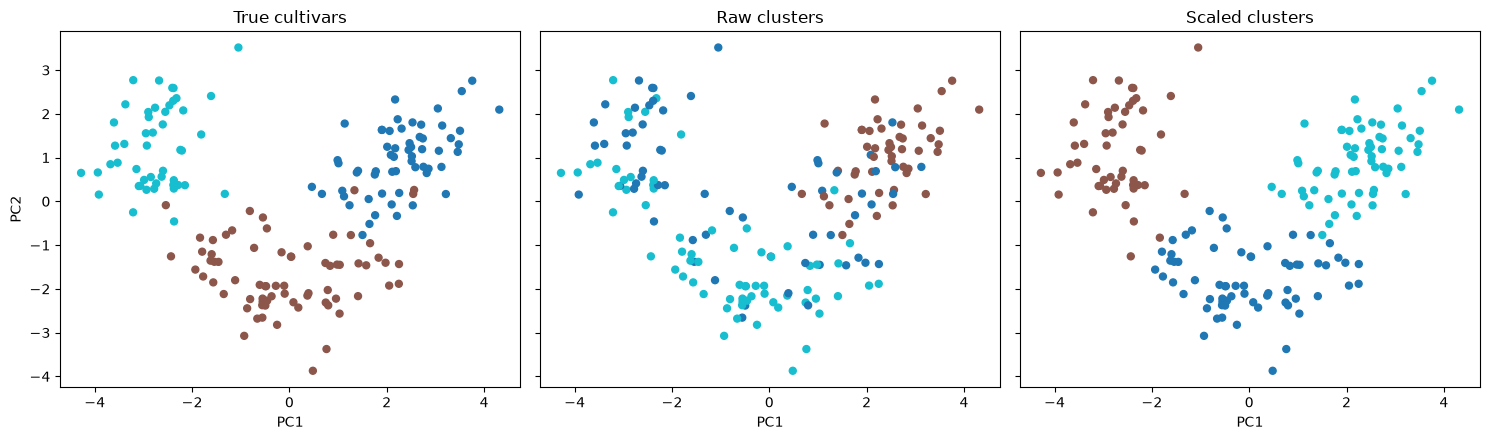

In [18]:
# YOUR CODE HERE
Z = PCA(n_components=2).fit_transform(Xw_s)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
for ax, lab, t in zip(axes, [yw, km_raw.labels_, km_sc.labels_],
                      ["True cultivars", "Raw clusters", "Scaled clusters"]):
    ax.scatter(Z[:, 0], Z[:, 1], c=lab, cmap="tab10", s=25)
    ax.set_title(t); ax.set_xlabel("PC1")
axes[0].set_ylabel("PC2")
plt.tight_layout(); plt.show()

**Questions** (answer with your own numbers)

(a) What happened when only the unit of Income changed? Explain it with the distance formula (which feature controls the distance now?).

(b) On the Wine data which feature dominated the raw distance and how big is its standard deviation compared with the others? What were the ARI values raw vs scaled?

(c) The silhouette was higher on the raw Wine data although the clustering was worse. Explain why a silhouette can mislead here and why comparing it between raw and scaled data is not fair.

(d) In a real project with no labels, how will you decide whether to scale? Write your rule in one or two sentences.



**Your answers:**

**(a)** Changing Income from k$ to dollars made it 1,000 times larger, causing it to dominate distance calculations. ARI dropped to **0.4897**, but scaling made both versions identical (ARI = 1.0).

**(b)** Proline dominated raw distances because its standard deviation (314.0) was much larger than other features. Scaling improved ARI from **0.3711 to 0.8975**.

**(c)** Raw data had a higher silhouette (0.5711) than scaled data (0.2849), but its clustering was worse. Raw distances were dominated by Proline, so silhouette alone did not indicate better clustering.

**(d)** I will scale features whenever they have different units or significantly different standard deviations to prevent large-scale features from dominating distance calculations.


---

## Part 5 — Outliers and Anomalies (20 minutes)

The lecture said 'one extreme point drags a centroid'. You will add one extreme customer, see the damage, and then catch it with a distance rule (the anomaly detection idea from the lecture).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Outlier | A point far away from all the others. K-Means uses means and squared distances, so one outlier has a big effect. | `A very large distance to the nearest centroid.` |
| Distance to own centroid | How far a point is from the centre of its cluster. Large = the point does not fit any group well. | `model.transform(X).min(axis=1)` |
| mean + 3 std rule | Flag a point if its distance is larger than the mean distance plus 3 standard deviations. | `d > d.mean() + 3*d.std()` |
| Anomaly detection | Using the clusters to find strange points (far from every centroid). | `Sort by the distance column.` |


### Task 5.1 — One extreme customer

Add one extra row to X2: Income = 400, Spending = 99. Use K = 5 on Income and Spending.

1. Fit KMeans (n_init=10, random_state=SEED) without and with the extra customer.
2. Print the cluster sizes, the centroids (sorted by income) and the ARI between the two results on the original 200 customers.
3. Draw the two clusterings side by side.


In [19]:
# YOUR CODE HERE
X2e = np.vstack([X2, [400, 99]])
km_a = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
km_b = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2e)

print("Without the extra customer: sizes", np.bincount(km_a.labels_).tolist())
print(km_a.cluster_centers_[np.argsort(km_a.cluster_centers_[:, 0])].round(1))
print("\nWith the extra customer: sizes", np.bincount(km_b.labels_).tolist())
print(km_b.cluster_centers_[np.argsort(km_b.cluster_centers_[:, 0])].round(1))
print("\nARI on the original 200 customers: %.4f" % adjusted_rand_score(km_a.labels_, km_b.labels_[:200]))


Without the extra customer: sizes [81, 39, 22, 35, 23]
[[25.7 79.4]
 [26.3 20.9]
 [55.3 49.5]
 [86.5 82.1]
 [88.2 17.1]]

With the extra customer: sizes [100, 1, 23, 39, 38]
[[ 26.3  20.9]
 [ 48.3  56.5]
 [ 86.5  82.1]
 [ 87.   18.6]
 [400.   99. ]]

ARI on the original 200 customers: 0.7532


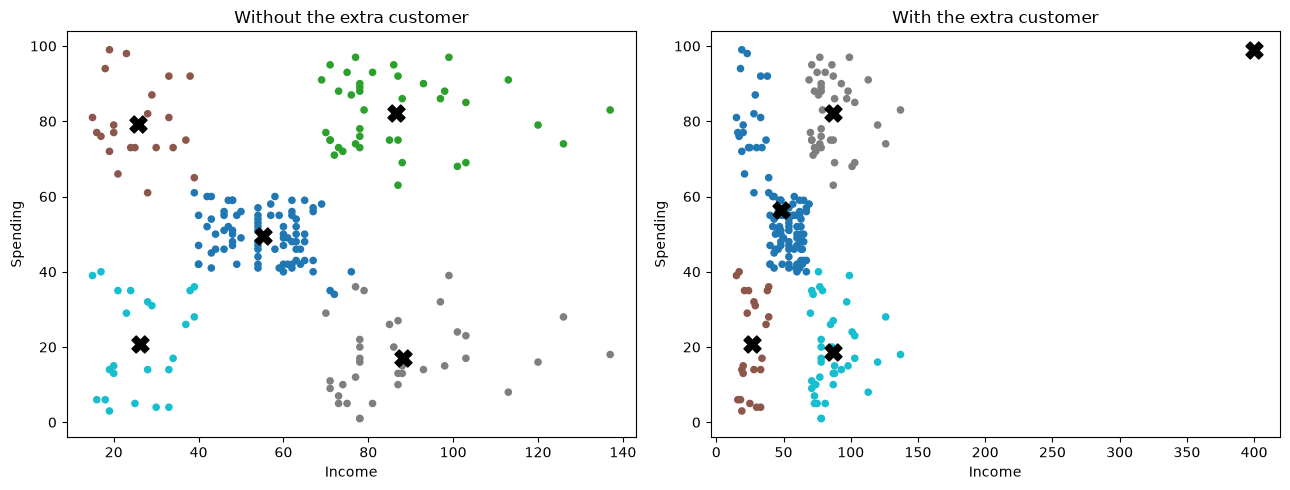

In [20]:
# YOUR CODE HERE
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, XX, m, t in [(axes[0], X2, km_a, "Without the extra customer"), (axes[1], X2e, km_b, "With the extra customer")]:
    ax.scatter(XX[:, 0], XX[:, 1], c=m.labels_, cmap="tab10", s=20)
    ax.scatter(m.cluster_centers_[:, 0], m.cluster_centers_[:, 1], c="black", marker="X", s=150)
    ax.set_title(t); ax.set_xlabel("Income"); ax.set_ylabel("Spending")
plt.tight_layout(); plt.show()

### Task 5.2 — Catch it and repair

Use the model fitted on the original 200 customers.

1. Compute every customer's distance to its nearest centroid, and the distance of the extra customer to the nearest centroid of the same model.
2. Apply the rule mean + 3 std (mean and std from the 200 real customers). How many real customers are flagged? Is the extra customer flagged?
3. Show the 5 real customers that are farthest from their centroid (CustomerID, Age, Income, Spending, Cluster, Distance).
4. Remove all flagged points, refit K = 5 and report the cluster sizes and the ARI against the original model on the 200 customers (use predict).


In [21]:
# YOUR CODE HERE
d = km_a.transform(X2).min(axis=1)                      # distance to own centroid
d_extra = km_a.transform([[400, 99]]).min(axis=1)[0]
limit = d.mean() + 3 * d.std()
flag = d > limit
print("Limit (mean + 3 std): %.2f" % limit)
print("Real customers flagged: %d   Extra customer distance: %.2f -> flagged: %s" % (flag.sum(), d_extra, d_extra > limit))

top = df[["CustomerID", "Age", "Income", "Spending"]].copy()
top["Cluster"] = km_a.labels_
top["Distance"] = d.round(2)
print("\n5 real customers farthest from their centroid:")
print(top.sort_values("Distance", ascending=False).head(5).to_string(index=False))

km_c = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2[~flag])
print("\nAfter removing flagged points: sizes", np.bincount(km_c.labels_).tolist())
print("ARI vs original model on the 200 customers: %.4f" % adjusted_rand_score(km_a.labels_, km_c.predict(X2)))


Limit (mean + 3 std): 34.80
Real customers flagged: 4   Extra customer distance: 313.92 -> flagged: True

5 real customers farthest from their centroid:
 CustomerID  Age  Income  Spending  Cluster  Distance
        200   30     137        83        1     50.47
        199   32     137        18        3     48.81
        198   32     126        74        1     40.29
        197   45     126        28        3     39.34
        196   35     120        79        1     33.61

After removing flagged points: sizes [80, 34, 23, 37, 22]
ARI vs original model on the 200 customers: 0.9847


**Questions** (answer with your own numbers)

(a) What did the single extreme customer do to the clusters? Which real groups were affected? Use sizes and centroids.

(b) How well did the rule detect the extra customer? The rule also flagged some real customers: are they mistakes in the data or something worth looking at? Look at their Income and Spending.

(c) Name two ways to deal with outliers and one risk of simply deleting them.



**Your answers:**

**(a)** The extra customer (400, 99) formed a separate cluster of size 1. It also caused two original groups to merge, and the ARI on the original 200 customers was **0.7532**.

**(b)** The outlier was detected with distance **313.92**, above the limit of **34.80**. Four real high-income customers were also flagged. After removing flagged points and refitting, ARI improved to **0.9847**.

**(c)** I would investigate unusual points before removing them. They could be errors or valuable customers, so they may need separate treatment, such as a VIP group, instead of deletion.


---

## Part 6 — From Clusters to Customer Segments (25 minutes)

Clusters are numbers (0, 1, 2 ...). The business needs names and actions. Cluster numbers are arbitrary labels: cluster 3 in one run has no meaning by itself. Use the original 200 customers and K = 5 on Income and Spending (random_state=SEED).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Cluster profile | The average of every feature inside each cluster, plus the cluster size. This is how you read what a cluster means. | `df.groupby('Cluster').agg(...)` |
| Segment | A cluster with a name and an action, for example 'High income / Low spending'. | `df['Cluster'].map(names)` |
| Crosstab | Counts or percentages of one category inside another (Gender inside Segment). | `pd.crosstab(a, b, normalize='index')` |


### Task 6.1 — Profile and name the segments

Make the clustering readable for a manager.

1. Add the cluster number to the data. Build a profile table: number of customers, mean Age, mean Income, mean Spending and % female for each cluster, sorted by Income.
2. Create segment names with a small rule (Income below 40 = Low, 70 or more = High, otherwise Mid; Spending below 35 = Low, 65 or more = High, otherwise Mid). Print the size of each segment.


In [22]:
# YOUR CODE HERE
km6 = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
df["Cluster"] = km6.labels_
df["Female"] = (df["Gender"] == "Female").astype(int)

profile = df.groupby("Cluster").agg(Customers=("Age", "size"), Age=("Age", "mean"),
                                    Income=("Income", "mean"), Spending=("Spending", "mean"),
                                    Pct_female=("Female", "mean")).sort_values("Income")
profile["Pct_female"] *= 100
print(profile.round(1))


         Customers   Age  Income  Spending  Pct_female
Cluster                                               
2               22  25.3    25.7      79.4        59.1
4               23  45.2    26.3      20.9        60.9
0               81  42.7    55.3      49.5        59.3
1               39  32.7    86.5      82.1        53.8
3               35  41.1    88.2      17.1        45.7


In [23]:
# YOUR CODE HERE
def seg_name(inc, spd):
    i = "Low" if inc < 40 else ("High" if inc >= 70 else "Mid")
    s = "Low" if spd < 35 else ("High" if spd >= 65 else "Mid")
    return f"{i} income / {s} spending"

names = {c: seg_name(r["Income"], r["Spending"]) for c, r in profile.iterrows()}
df["Segment"] = df["Cluster"].map(names)
print(df["Segment"].value_counts())


Segment
Mid income / Mid spending      81
High income / High spending    39
High income / Low spending     35
Low income / Low spending      23
Low income / High spending     22
Name: count, dtype: int64


### Task 6.2 — Does Gender matter? Does Age matter?

Gender and Age were not used in the clusters. Check whether they would add something.

1. Show the % of women in each segment and the overall %.
2. Scale Age, Income and Spending together and print the average silhouette for K = 2 to 8.


In [24]:
# YOUR CODE HERE
print("% women in each segment:")
print((df.groupby("Segment")["Female"].mean() * 100).round(1))
print("Overall: %.1f%%" % (df["Female"].mean() * 100))

X3 = StandardScaler().fit_transform(df[["Age", "Income", "Spending"]])
sil3 = {}
for k in range(2, 9):
    sil3[k] = silhouette_score(X3, KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X3))
print("\nSilhouette with Age, Income, Spending (scaled):")
print(pd.Series(sil3).round(4))

% women in each segment:
Segment
High income / High spending    53.8
High income / Low spending     45.7
Low income / High spending     59.1
Low income / Low spending      60.9
Mid income / Mid spending      59.3
Name: Female, dtype: float64
Overall: 56.0%

Silhouette with Age, Income, Spending (scaled):
2    0.3355
3    0.3578
4    0.4040
5    0.4166
6    0.4284
7    0.4172
8    0.4082
dtype: float64


### Task 6.3 — A three-feature alternative

Cluster the scaled Age, Income and Spending with the best K from the table above.

1. Fit it, build its profile table (size, Age, Income, Spending) sorted by Age.
2. Print the ARI between this segmentation and your 2-feature K = 5 segmentation.


In [25]:
# YOUR CODE HERE
best_k = max(sil3, key=sil3.get)
lab3 = KMeans(n_clusters=best_k, n_init=10, random_state=SEED).fit_predict(X3)
df["Cluster3"] = lab3
print("Best K:", best_k)
print(df.groupby("Cluster3").agg(Customers=("Age", "size"), Age=("Age", "mean"),
                                 Income=("Income", "mean"), Spending=("Spending", "mean")).sort_values("Age").round(1))
print("\nARI vs the 2-feature K = 5 segmentation: %.4f" % adjusted_rand_score(df["Cluster"], lab3))


Best K: 6
          Customers   Age  Income  Spending
Cluster3                                   
4                23  25.0    25.3      77.6
1                39  26.8    57.1      48.1
3                39  32.7    86.5      82.1
2                33  41.9    88.9      17.0
5                21  45.5    26.3      19.4
0                45  56.3    54.3      49.1

ARI vs the 2-feature K = 5 segmentation: 0.7002


**Questions** (answer with your own numbers)

(a) Give each of the 5 segments a short business name and one concrete action (an offer or a message). Use the numbers from your profile table.

(b) Which segment is the most valuable now and which one is the biggest opportunity? Why?

(c) Does Gender help to separate the segments? Quote the percentages.

(d) Does adding Age change the story? Which segmentation would you present and why? (Careful: silhouette values from different feature sets are not directly comparable.)



**Your answers:**

**(a)**  
- **Mid/Mid:** Average shoppers (81) – Offer loyalty points.
- **High/High:** VIP big spenders (39) – Give early access to new products.
- **High/Low:** Rich but careful (35) – Send premium personal offers.
- **Low/High:** Young enthusiasts (22) – Offer student or trend discounts.
- **Low/Low:** Budget shoppers (23) – Provide discount coupons.

**(b)** The most valuable segment is **High/High**, while **High/Low** offers the biggest growth opportunity because customers have high incomes but spend less.

**(c)** Gender does not significantly distinguish the segments because female percentages (45.7%–60.9%) are close to the overall 56%.

**(d)** Age adds some detail by splitting the Mid/Mid group into younger and older customers (ARI = 0.7002). However, I prefer the simpler **K=5 segmentation** using Income and Spending because it is easier to understand and apply marketing strategies to.


---

## Part 7 — Final Output and Wrap-Up (15 minutes)

Package your result like you would give it to a marketing team.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Deliverable | A file someone else can use without running your notebook. | `df.to_csv('customer_segments.csv', index=False)` |


### Task 7.1 — Save the segments

Create a CSV with CustomerID, Age, Gender, Income, Spending, Cluster and Segment.

1. Save it as customer_segments.csv and print the number of customers per segment.
2. Write a 6-8 line Executive Summary (Markdown): the K you chose and the evidence for it, the segments and their sizes, one action per segment (short), how you handled scaling and outliers, and one limitation.


In [26]:
# YOUR CODE HERE
out = df[["CustomerID", "Age", "Gender", "Income", "Spending", "Cluster", "Segment"]]
out.to_csv("customer_segments.csv", index=False)
print(out["Segment"].value_counts())

Segment
Mid income / Mid spending      81
High income / High spending    39
High income / Low spending     35
Low income / Low spending      23
Low income / High spending     22
Name: count, dtype: int64


**Executive Summary** (6-8 lines)

I clustered 200 mall customers using Income and Spending with K=5. K=5 gave the highest silhouette score (0.5539) and showed an elbow in the inertia curve. The five segments were Mid/Mid (81), High/High (39), High/Low (35), Low/Low (23), and Low/High (22). I recommended loyalty points, early access, premium offers, coupons, and student discounts for these groups, respectively. I did not scale Income and Spending because they have similar ranges, but the Age and Income test showed that scaling matters (ARI 0.49 raw vs 1.0 scaled). I used `n_init=10` for more reliable clustering because a single random start reached the best result only 33% of the time. An extreme customer changed the clustering (ARI 0.75), so I checked for outliers. A limitation is that K-Means uses no true labels, so the segments are evaluated through silhouette scores and practical interpretation.


**Questions** (answer with your own numbers)

(a) What was the most surprising result in this lab?

(b) If you had one more hour, what would you try next?



**Your answers:**

(a) The most surprising result was that only changing the Income unit from k$ to dollars changed the clusters (ARI 0.4897), and that the Wine silhouette was higher for the worse raw clustering (0.5711 vs 0.2849).

(b) I would try another clustering method, such as DBSCAN, which can find outliers by itself, and compare it with K-Means.



---